# Flare and ghosts: double reflections in a camera lens

Point a camera at the Sun and the frame fills with copies of the iris:
coloured polygons on a line through the centre of the frame, some large and
faint, a few small and bright. These are ghosts. Each one is light that was
reflected twice inside the lens, once backwards at a surface $j$ and once
forwards again at an earlier surface $i$, and so reaches the sensor along a
path the designer never meant it to take. Together with the light
scattered by dust and the barrel, they lower the contrast of the whole
frame (veiling glare).

An uncoated glass surface reflects about 4 to 7 % of the light. A lens with
ten such surfaces has 45 ghost paths, and 10 more that start with a
reflection at the sensor. Antireflection coatings, thin films a fraction of a
wavelength thick, cut each reflection by one or two orders of magnitude.
Since a ghost is reflected twice, it falls with the square of that. The
films also give the ghosts their colours, because a coating reflects most at
the ends of its band.

This notebook covers:

1. every ghost path of the 50 mm double Gauss lens of notebook 90, traced
   with the polarization ray trace of notebook 20 and the thin film
   coatings of `pyoptics.coatings`, and checked against the product of the
   Fresnel factors,
2. three coatings on every air-glass surface: none, a single quarter wave
   layer of MgF2, and a three layer broadband design,
3. the paraxial ghost analysis: how big and how bright each ghost is, why a
   ghost that focuses near the sensor is dangerous, and why ghosts grow as
   $N^2$ when the lens is stopped down,
4. a rendered image of the Sun in the corner of the frame, with all 55
   ghosts in colour for the three coatings, and the veiling glare they add.

Diffraction at the iris (the sunstar of notebook 91) and scattering are
left out.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

from pyoptics import colour
from pyoptics import photography as ph
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(92)
DESIGNS = ("uncoated", "MgF2", "multilayer")
DESIGN_COLORS = dict(zip(DESIGNS, (GREY, PURPLE, GREEN)))

## 1. Ghost paths

The lens has 11 surfaces. The stop (surface 5) is not a reflector, which
leaves 10 surfaces between media of different index, plus the sensor, whose
cover glass and microlenses reflect a few percent too (modelled here as a
plain interface to $n = 1.65$). A ghost path $(j, i)$ with $i < j$ is

- forward through surfaces $0, \dots, j-1$,
- reflected at $j$ (the sensor when $j = 11$),
- backward through $j-1, \dots, i+1$,
- reflected at $i$,
- forward through $i+1, \dots, 10$ to the sensor.

`ph.ghost_paths()` lists all of them, and `ph.ghost_system()` unfolds a
path into an ordinary `raytrace.System`: the surfaces after the first
reflection are copies with negative thicknesses and the two reflecting
surfaces become mirrors. The coating of each surface, seen from the side
the light comes from, gives the Fresnel coefficients at every pass, and
`System.trace_polarization()` carries the full polarization state through
the path (`ph.trace_flare()`).

For a thin beam along the axis every surface is met at normal incidence,
and the power of a ghost must be $R_j R_i$ times the transmittance of all
the surfaces it passes:

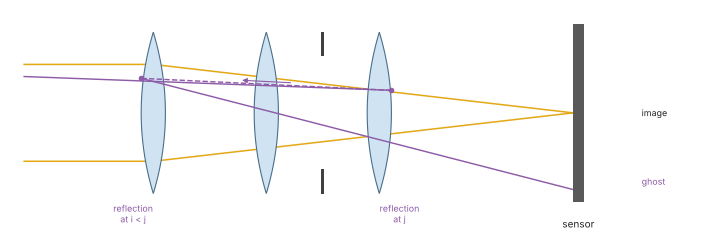

In [2]:
fig, ax = plt.subplots(figsize=(12, 3.8))
sketch.ghost_reflections(ax)
plt.show()

In [3]:
lens = ph.double_gauss(8)                    # the 50 mm double Gauss of notebook 90, stopped down to f/8
paths = ph.ghost_paths(lens)
n_lens = sum(1 for j, i in paths if j < len(lens.surfaces))
print("{} reflecting surfaces: {} ghost paths in the lens and {} with the sensor, {} in all".format(
    sum(1 for k in range(len(lens.surfaces)) if lens.n[k] != lens.n[k + 1]), n_lens, len(paths) - n_lens,
    len(paths)))

# a thin axial beam (0.3 mm radius, so that no path clips at the f/8 stop): the polarization ray trace against R_j R_i times all transmittances
n = [float(np.real(v)) for v in lens.n]
R = lambda a, b: ((a - b)/(a + b))**2
rays, w = ph.flare_rays(lens, 0.0, n=41, radius=0.3)
x, y, p = ph.trace_flare(lens, rays, w)
T_direct = p.sum()/w.sum()
N_s = len(lens.surfaces)
print("direct: traced T = {:.6f}, product of (1 - R) = {:.6f}".format(
    T_direct, np.prod([1 - R(n[k], n[k + 1]) for k in range(N_s)])))
dev = []
for j, i in paths:
    x, y, p = ph.trace_flare(lens, rays, w, path=(j, i))
    Tg = (R(n[j], n[j + 1]) if j < N_s else R(1.0, 1.65))*R(n[i], n[i + 1])
    for k in list(range(min(j, N_s))) + list(range(i + 1, min(j, N_s))) + list(range(i + 1, N_s)):
        Tg *= 1 - R(n[k], n[k + 1])
    dev.append(abs(p.sum()/w.sum()/Tg - 1))
    if (j, i) in ((1, 0), (4, 2), (10, 8), (9, 1), (11, 10), (11, 0)):
        print("ghost {:8s} traced {:.4e}   R_j R_i prod(T) = {:.4e}".format(str((j, i)), p.sum()/w.sum(), Tg))
print("largest relative deviation over all {} paths: {:.1e}".format(len(paths), max(dev)))

10 reflecting surfaces: 45 ghost paths in the lens and 10 with the sensor, 55 in all
direct: traced T = 0.582620, product of (1 - R) = 0.582620
ghost (1, 0)   traced 2.5331e-03   R_j R_i prod(T) = 2.5331e-03


ghost (4, 2)   traced 2.4335e-03   R_j R_i prod(T) = 2.4335e-03


ghost (9, 1)   traced 1.4839e-03   R_j R_i prod(T) = 1.4839e-03


ghost (10, 8)  traced 2.2100e-03   R_j R_i prod(T) = 2.2100e-03
ghost (11, 0)  traced 8.9923e-04   R_j R_i prod(T) = 8.9923e-04


ghost (11, 10) traced 2.3113e-03   R_j R_i prod(T) = 2.3113e-03
largest relative deviation over all 55 paths: 3.1e-07


The traced powers agree with the product of the Fresnel factors to a
few parts in $10^7$ for all 55 paths. The direct image keeps 58 % of the
light, and each ghost takes a few tenths of a percent. A beam wider than
0.3 mm would be clipped for some paths, because the ghost passes the f/8
stop three times.

## 2. Antireflection coatings

A single layer of index $n_1$ and optical thickness $\lambda_0/4$ on glass
of index $n_g$ sends back two reflections of opposite phase, one from the
air side and one from the glass side. They cancel at $\lambda_0$ when
$n_1 = \sqrt{n_g}$. MgF2 ($n_1 = 1.38$) is the classic choice, close to the
ideal 1.30 for N-LAK9. A stack of three layers of high, medium and low index
(Al2O3, ZrO2, MgF2) has enough freedom to hold the reflectance low over the
whole visible band. Here its thicknesses were optimized for a mean
reflectance over 420 to 680 nm on $n = 1.68$ (`ph.AR_DESIGNS`), and
`ph.ar_coatings()` puts a design on every air-glass surface of the lens,
mirrored where the light leaves the glass.

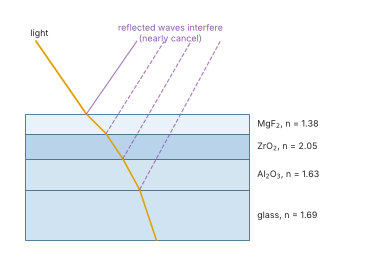

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
sketch.ar_coating_layers(ax)
plt.show()

design        mean R (420-680 nm)   R at 550 nm   ghost factor R^2 vs uncoated
uncoated          6.594 %             6.594 %       1.0e+00
MgF2              0.682 %             0.352 %       1.1e-02
multilayer        0.166 %             0.289 %       6.3e-04


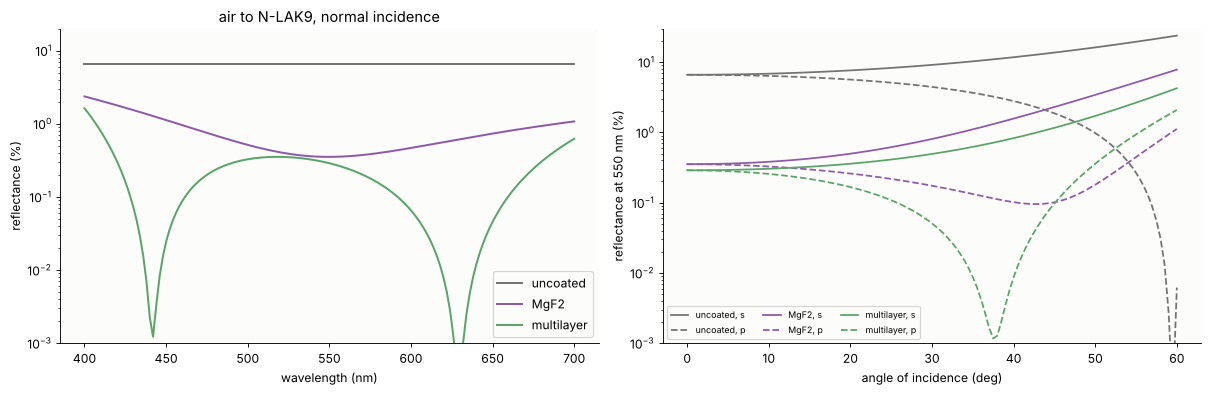

uncoated   : lens transmits 58.3 %, the 55 ghost paths together 6.65e-02 of the light (1.14e-01 relative)
MgF2       : lens transmits 96.6 %, the 55 ghost paths together 2.47e-03 of the light (2.56e-03 relative)
multilayer : lens transmits 99.0 %, the 55 ghost paths together 6.18e-04 of the light (6.24e-04 relative)


In [5]:
n_glass = float(np.real(lens.n[1]))              # N-LAK9 at the d line
lam_nm = np.linspace(400, 700, 151)
from pyoptics.coatings import Coating, Layer
stacks = {d: Coating([Layer(nl, t) for nl, t in ph.AR_DESIGNS[d]]) for d in DESIGNS}
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
print("design        mean R (420-680 nm)   R at 550 nm   ghost factor R^2 vs uncoated")
R_mean = {}
for d, st in stacks.items():
    Rl = np.array([st.power(0.0, 1.0, n_glass, l*1e-6)["R_s"] for l in lam_nm]).real
    band = (lam_nm >= 420) & (lam_nm <= 680)
    R_mean[d] = Rl[band].mean()
    ax[0].semilogy(lam_nm, 100*Rl, color=DESIGN_COLORS[d], lw=1.8, label=d)
    print("{:12s}     {:6.3f} %            {:6.3f} %       {:.1e}".format(
        d, 100*R_mean[d], 100*st.power(0.0, 1.0, n_glass, 550e-6)["R_s"].real,
        (R_mean[d]/R_mean["uncoated"])**2))
ax[0].set_xlabel("wavelength (nm)"); ax[0].set_ylabel("reflectance (%)"); ax[0].set_ylim(1e-3, 20)
ax[0].set_title("air to N-LAK9, normal incidence"); ax[0].legend()
th = np.radians(np.linspace(0, 60, 121))
for d, st in stacks.items():
    pw = st.power(th, 1.0, n_glass, 550e-6)
    ax[1].plot(np.degrees(th), 100*pw["R_s"].real, color=DESIGN_COLORS[d], lw=1.6, label=d + ", s")
    ax[1].plot(np.degrees(th), 100*pw["R_p"].real, color=DESIGN_COLORS[d], lw=1.6, ls="--", label=d + ", p")
ax[1].set_yscale("log"); ax[1].set_ylim(1e-3, 30)
ax[1].set_xlabel("angle of incidence (deg)"); ax[1].set_ylabel("reflectance at 550 nm (%)")
ax[1].legend(ncol=3, fontsize=8)
plt.show()

# all ghosts together, at normal incidence (d line)
for d in DESIGNS:
    info, Td = ph.ghost_analysis(lens, ph.ar_coatings(lens, d))
    tot = sum(g.transmittance for g in info)
    print("{:11s}: lens transmits {:.1f} %, the 55 ghost paths together {:.2e} of the light ({:.2e} relative)".format(
        d, 100*Td, tot, tot/Td))

The single layer reflects 0.35 % at its design wavelength but more
towards both ends of the band, which is why the ghosts of single coated
lenses look purple: they are the blue and red that the coating does not
cancel. The multilayer stays below 0.36 % from 418 to 686 nm and has two
zeros, at 442 and 629 nm. What remains peaks in the middle of the band, so
its ghosts are green, the familiar colour of modern multicoated lenses.
Both coatings get worse at steep angles, more so for s than for p.

Because each ghost has two reflections, a coating that divides $R$ by 10
divides every ghost by about 100. The 55 paths together carry 11 % of the
light that reaches the sensor in the uncoated lens, 0.26 % with MgF2, and
0.06 % with the multilayer. The coatings also raise the transmittance of the
lens from 58 % to 97 and 99 %, which was the reason they were first
introduced, around 1940.

## 3. Where a ghost focuses, and the F-number

The size of a ghost follows from paraxial optics. A ray that enters
parallel to the axis at height $y_{\rm in}$ reaches the sensor at
$a\,y_{\rm in}$ after the ghost path, so a collimated beam that fills the
aperture becomes a disk of radius $\vert a\vert y_{\rm in}$ (or an image of the iris,
when the ghost passes the stop). If $a$ is small, the ghost is focused near
the sensor: a small, bright spot. If $\vert a\vert$ is about 1, it covers a
large part of the frame and is faint.

A source of irradiance $E_0$ at the lens sends $E_0\pi y_{\rm in}^2 R_iR_jT_g$
into a disk of area $\pi a^2y_{\rm in}^2$, so the ghost irradiance
$E_g = E_0R_iR_jT_g/a^2$ does not depend on the aperture. The image of a white
diffuse surface lit by the same source is $E_w = E_0T/4N^2$. The ratio

$$\frac{E_g}{E_w} = \frac{4N^2\,R_iR_jT_g}{T\,a^2}$$

grows as $N^2$: stopping down does not change the ghost but darkens
everything else, and the exposure is set by the everything else
(`ph.ghost_analysis()`). For comparison, the image of the Sun itself is
$1/\theta_\odot^2 \approx 4.6\times 10^4$ times the white level.

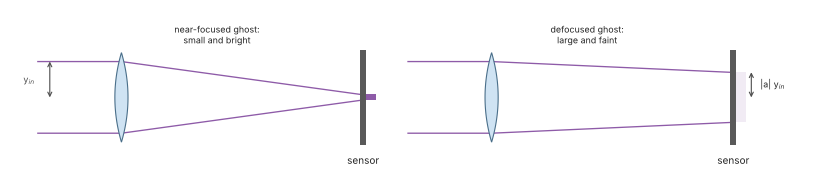

In [6]:
fig, ax = plt.subplots(figsize=(13, 3.2))
sketch.ghost_focus(ax)
plt.show()

In [7]:
# paraxial ghost analysis of the uncoated lens at f/8 against traced ghosts of an axial point source
info, Td = ph.ghost_analysis(lens)
info.sort(key=lambda g: -g.irradiance)
d = ph.ghost_footprint(lens, 0.0, None, n_rays=20000, rng=rng)
E_white = d.power.sum()/(np.pi*ph.DOUBLE_GAUSS_F**2)        # image of a white surface lit by the source
h = lens.paraxial().ep_radius
print(" path       a       ghost focus   paraxial E/E_w   traced E/E_w   rms radius: traced   paraxial (mm)")
print("                    (mm from sensor)")
for g in info[:14]:
    fp = ph.ghost_footprint(lens, 0.0, g.path, n_rays=20000, rng=rng)
    r = np.hypot(fp.x, fp.y)
    rms = np.sqrt(np.average(r**2, weights=fp.power))
    E = fp.power.sum()/(2*np.pi*rms**2)/E_white                  # mean over the disk of radius sqrt(2) rms
    print("{:9s} {:7.4f}   {:8.2f}       {:10.3g}     {:10.3g}        {:6.3f}       {:6.3f}".format(
        str(g.path), g.magnification, g.focus, g.irradiance, E, rms, abs(g.magnification)*h/np.sqrt(2)))

 path       a       ghost focus   paraxial E/E_w   traced E/E_w   rms radius: traced   paraxial (mm)
                    (mm from sensor)


(10, 8)    0.0030       0.20         1.07e+05       1.48e+04         0.018        0.007


(9, 1)     0.0050       0.16         2.62e+04       1.03e+04         0.011        0.011


(6, 0)    -0.2682      19.00             9.93             12         0.542        0.593


(2, 0)    -0.3673     -12.65              7.2           6.51         0.757        0.812


(11, 1)    0.3923     -17.25             2.94           2.97         0.870        0.867


... (5 outputs left out)

(6, 4)    -1.2873    -274.53             0.62          0.651         2.789        2.845


(8, 4)     1.3090     -40.23            0.547          0.535         2.944        2.893


(10, 6)   -1.3291     -43.51            0.461          0.457         2.963        2.937


(8, 6)    -1.7668     -43.44            0.343          0.342         3.930        3.904


The table is sorted by the paraxial ghost irradiance. For the defocused
ghosts the paraxial values and the traced ones (the mean irradiance over a
disk of radius $\sqrt 2$ times the rms radius) agree to a few percent, and so
do the radii. Two ghosts are close to focus: $(10, 8)$, reflected off the
rear surface of the last lens and then off the rear surface of the cemented
doublet in front of it, focuses 0.2 mm from the sensor, and $(9, 1)$ 0.16 mm. Paraxially they would be $10^5$ times
white. The ray trace finds them limited by aberrations to 1.5 and
$1.0\times10^4$, still a fifth to a third of the Sun itself. Such focused
ghosts are what lens designers hunt for with ghost focus programs, by
bending elements until $\vert a\vert$ grows.

The $N^2$ law is checked by tracing the same ghosts from f/4 to f/16:

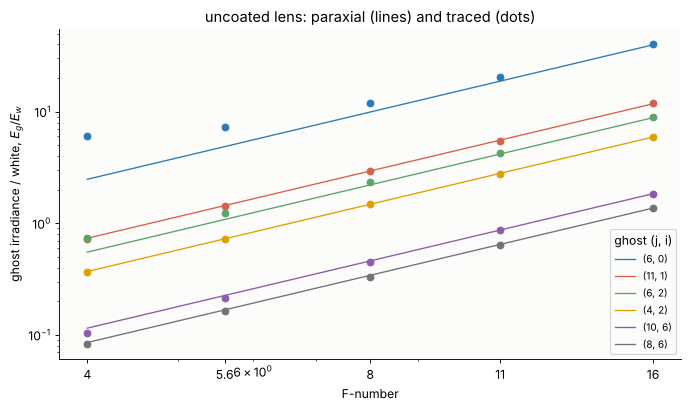

f/4    traced/paraxial: 2.42 0.99 1.34 1.00 0.90 0.97
f/5.6  traced/paraxial: 1.49 1.00 1.15 1.01 0.96 0.98
f/8    traced/paraxial: 1.21 0.99 1.06 1.00 0.98 0.97
f/11   traced/paraxial: 1.09 0.99 1.02 0.99 1.00 0.99
f/16   traced/paraxial: 1.03 1.01 1.02 1.00 1.00 0.99


In [8]:
# ghost irradiance relative to white against the F-number: 4 N^2 R_i R_j T_g/(T a^2)
F_NUMBERS = [4, 5.6, 8, 11, 16]
picks = [(6, 0), (11, 1), (6, 2), (4, 2), (10, 6), (8, 6)]
fig, ax = plt.subplots(figsize=(8.5, 5), layout="constrained")
cols = [BLUE, RED, GREEN, ORANGE, PURPLE, GREY]
ratios = []
for path, col in zip(picks, cols):
    par, tr = [], []
    for N in F_NUMBERS:
        sysN = ph.double_gauss(N)
        g = [q for q in ph.ghost_analysis(sysN)[0] if q.path == path][0]
        dN = ph.ghost_footprint(sysN, 0.0, None, n_rays=8000, rng=rng)
        Ew = dN.power.sum()/(np.pi*ph.DOUBLE_GAUSS_F**2)
        fp = ph.ghost_footprint(sysN, 0.0, path, n_rays=12000, rng=rng)
        r2 = np.average(fp.x**2 + fp.y**2, weights=fp.power)
        par.append(g.irradiance); tr.append(fp.power.sum()/(2*np.pi*r2)/Ew)
    ratios.append(np.array(tr)/np.array(par))
    ax.loglog(F_NUMBERS, par, color=col, lw=1.2, label=str(path))
    ax.loglog(F_NUMBERS, tr, "o", color=col, ms=6)
ax.set_xticks(F_NUMBERS); ax.set_xticklabels([str(N) for N in F_NUMBERS])
ax.set_xlabel("F-number"); ax.set_ylabel(r"ghost irradiance / white, $E_g/E_w$")
ax.set_title("uncoated lens: paraxial (lines) and traced (dots)"); ax.legend(title="ghost (j, i)", fontsize=9)
plt.show()
ratios = np.array(ratios)
for N, col in zip(F_NUMBERS, ratios.T):
    print("f/{:<4g} traced/paraxial: {}".format(N, " ".join("{:.2f}".format(c) for c in col)))

At f/11 and f/16 the traced ghosts follow the paraxial law (the $N^2$
slope) within 9 %, most of them within 2 %. Opening up, the ghosts $(6, 0)$
and $(6, 2)$ become brighter than paraxial, 2.4 and 1.3 times at f/4: the
spherical aberration of their ghost paths bunches the light into a smaller
blur. The other four stay within 10 % at every F-number.

## 4. The Sun in the frame

The Sun is placed at $(-9°, 6°)$ in the field of view, about two thirds of
the way to the corner of a 36 × 24 mm frame, with the lens at f/8 and an
iris of seven straight blades. For a centred lens every ghost lies on the
line from the Sun's image through the centre of the frame:

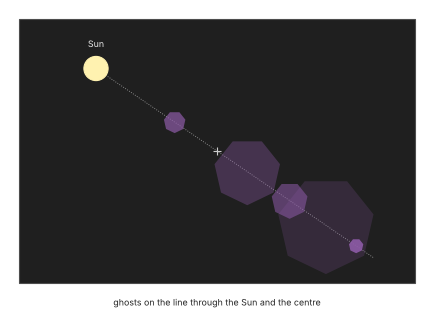

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
sketch.flare_scene(ax)
plt.show()

Off the axis the angles of incidence differ from surface to surface and
the coatings act differently on s and p. The rendering therefore uses the
coating reflectances for s and p separately, each tabulated against angle
for every wavelength, and multiplied along each ray (`ph.ghost_spectra()`).
This ignores the mixing of s and p between surfaces, which the full
polarization ray trace includes. The check below compares the two at the d
line and finds them within 0.4 %:

In [10]:
# the Sun at (-9, 6) deg in the frame; the brightest ghosts traced both ways at the d line:
# full polarization ray trace vs separate s and p chains of the coating reflectances
field = (np.radians(-9.0), np.radians(6.0))
r_stop = lens.surfaces[lens.stop_index].semi_diameter
iris = (7, ph.iris_apothem(7, np.pi*r_stop**2), np.inf, np.pi/2)      # seven straight blades at f/8
coat = {d: ph.ar_coatings(lens, d) for d in DESIGNS}
print("ghost      design       PRT power    s/p chains   ratio    (power in units of the incident ray weights)")
worst = 0.0
for path in [(10, 8), (4, 2), (6, 0), (11, 9), (8, 6)]:
    for d in ("uncoated", "multilayer"):
        fp = ph.ghost_footprint(lens, field, path, coat[d], n_rays=8000, rng=rng, iris_shape=iris,
                                wavelengths_nm=[ph.D_LINE*1e6])
        ratio = fp.spectrum[:, 0].sum()/fp.power.sum()
        worst = max(worst, abs(ratio - 1))
        print("{:9s}  {:11s}  {:.3e}    {:.3e}    {:.4f}".format(str(path), d, fp.power.sum(),
                                                               fp.spectrum[:, 0].sum(), ratio))
print("largest difference: {:.1e}".format(worst))

ghost      design       PRT power    s/p chains   ratio    (power in units of the incident ray weights)


(10, 8)    uncoated     6.603e-02    6.601e-02    0.9997


(10, 8)    multilayer   3.666e-05    3.665e-05    0.9999
(4, 2)     uncoated     8.860e-02    8.856e-02    0.9995


(4, 2)     multilayer   4.956e-05    4.955e-05    0.9997


(6, 0)     uncoated     3.330e-02    3.329e-02    0.9998


(6, 0)     multilayer   2.239e-05    2.248e-05    1.0040
(11, 9)    uncoated     5.976e-03    5.974e-03    0.9997


(11, 9)    multilayer   1.433e-04    1.433e-04    1.0006
(8, 6)     uncoated     7.284e-02    7.283e-02    0.9997


(8, 6)     multilayer   3.765e-05    3.766e-05    1.0004
largest difference: 4.0e-03


Each ghost is sampled adaptively (`ph.ghost_footprint()`). A coarse grid
of rays over the front of the lens finds the region that passes the whole
path, including the iris at every pass of the stop, and dense random rays
then fill only that region, with directions spread over the Sun's disk.
The images are histograms of the rays at nine wavelengths, scaled to the
image of a white surface lit by the Sun, and turned into sRGB under a
5778 K spectrum, white balanced, with a soft shoulder so that the white
level is light grey and the Sun saturates:

traced 56 paths x 3 coatings in 21 s


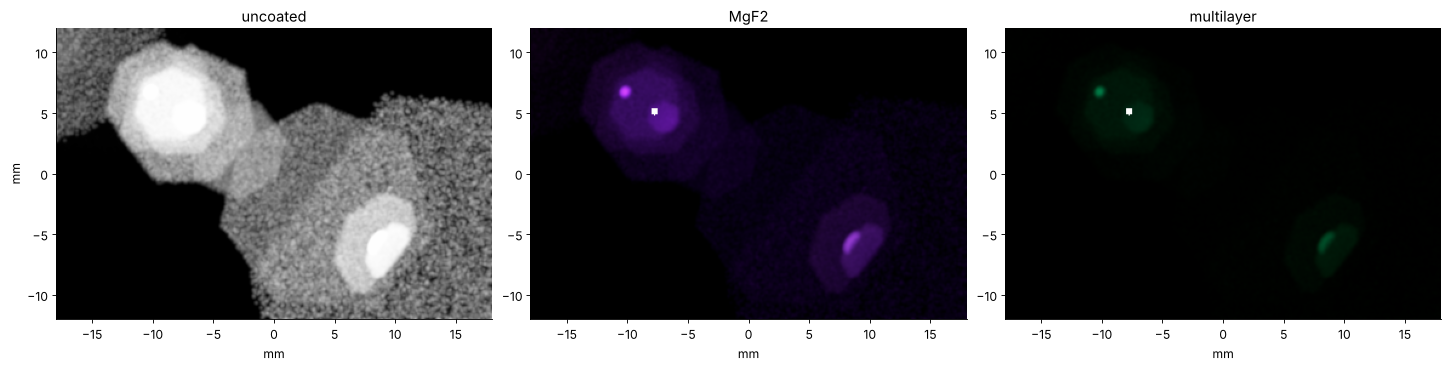

In [11]:
# all 55 ghosts and the direct image of the Sun, 9 wavelengths, three coatings
lam = np.linspace(420, 680, 9)
pix = 0.1
xe = np.arange(-18, 18 + pix/2, pix); ye = np.arange(-12, 12 + pix/2, pix)
images = {d: np.zeros((len(lam), len(ye) - 1, len(xe) - 1)) for d in DESIGNS}
ghost_only = {d: np.zeros_like(images[d]) for d in DESIGNS}
P_direct, per_ghost = {}, {d: {} for d in DESIGNS}
t0 = time.time()
for path in [None] + paths:
    x, y, specs = ph.ghost_spectra(lens, field, path, [coat[d] for d in DESIGNS], lam,
                                   n_rays=40000 if path is None else 24000, rng=rng,
                                   source_radius=ph.SUN_RADIUS, iris_shape=iris)
    for d, sp in zip(DESIGNS, specs):
        if path is None:
            P_direct[d] = sp.sum(axis=0)
        else:
            per_ghost[d][path] = sp.sum(axis=0)
        for q in range(len(lam)):
            H, _, _ = np.histogram2d(y, x, bins=[ye, xe], weights=sp[:, q])
            H = H/pix**2
            if path is not None:
                H = gaussian_filter(H, 1.0)                 # smooth the ray noise of the broad ghosts
                ghost_only[d][q] += H
            images[d][q] += H
print("traced {} paths x 3 coatings in {:.0f} s".format(len(paths) + 1, time.time() - t0))

sun = colour.planck(lam, 5778.0)
cmf = colour.cie_xyz(lam)
white_rgb = colour.xyz_to_linear_srgb((cmf*sun).sum(axis=1))

def to_srgb(E_rel):
    """Spectral image relative to white (per wavelength) to sRGB under sunlight, white balanced,
    a white page at 1 - 1/e, with a shoulder."""
    XYZ = np.tensordot(cmf*sun, E_rel, axes=(1, 0))
    rgb = colour.xyz_to_linear_srgb(np.moveaxis(XYZ, 0, -1))/white_rgb
    return colour.srgb_gamma(1 - np.exp(-np.clip(rgb, 0, None)))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6), layout="constrained")
for a, d in zip(ax, DESIGNS):
    Ew = P_direct[d]/(np.pi*ph.DOUBLE_GAUSS_F**2)
    a.imshow(to_srgb(images[d]/Ew[:, None, None]), extent=[xe[0], xe[-1], ye[0], ye[-1]], origin="lower")
    a.set_title(d); a.set_xlabel("mm")
ax[0].set_ylabel("mm")
plt.show()

Without coatings the frame is washed out. Two broad, overlapping groups
of heptagons surround the Sun and its mirror point on the far side of the
centre, and they are bright enough to saturate. With MgF2 the same
ghosts are faint purple shapes. Two features stand out: a small bright
spot next to the Sun, which is the near-focused ghost $(10, 8)$ of
section 3, and a bright crescent on the opposite side. The other
near-focused ghost, $(9, 1)$, is cut off by the stop at this angle. With the multilayer they are green and
about 3.5 times fainter again.

design        mean ghost light / white   brightest ghost pixel / white
uncoated           3.80e-01                   91.492
MgF2               2.31e-03                    0.516
multilayer         6.59e-04                    0.144


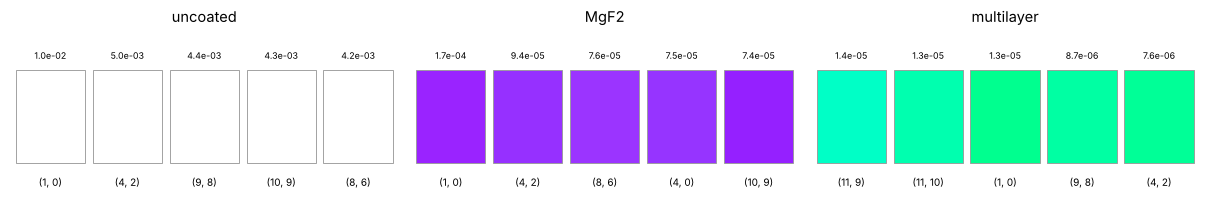

In [12]:
# veiling glare: the ghost light averaged over the frame, and the brightest ghosts
print("design        mean ghost light / white   brightest ghost pixel / white")
for d in DESIGNS:
    Ew = P_direct[d]/(np.pi*ph.DOUBLE_GAUSS_F**2)
    Erel = ghost_only[d]/Ew[:, None, None]
    Y = np.tensordot(cmf[1]*sun, Erel, axes=(0, 0))/(cmf[1]*sun).sum()      # luminance weighted
    print("{:11s}      {:10.2e}                 {:8.3f}".format(d, Y.mean(), Y.max()))

# colours of the five strongest ghosts of each design (spectrum under sunlight)
fig, ax = plt.subplots(1, 3, figsize=(15, 2.6), layout="constrained")
for a, d in zip(ax, DESIGNS):
    tot = {p: s.sum() for p, s in per_ghost[d].items()}
    top = sorted(tot, key=lambda p: -tot[p])[:5]
    for k, p in enumerate(top):
        spec = per_ghost[d][p]/P_direct[d]                        # relative to the direct image, per wavelength
        rgb = colour.xyz_to_linear_srgb((cmf*sun*spec).sum(axis=1))/white_rgb
        rgb = colour.srgb_gamma(np.clip(rgb/rgb.max(), 0, 1))
        a.add_patch(plt.Rectangle((k, 0), 0.9, 1, facecolor=rgb, edgecolor="0.6", lw=0.8))
        a.text(k + 0.45, -0.25, str(p), ha="center", fontsize=9)
        a.text(k + 0.45, 1.12, "{:.1e}".format(spec.mean()), ha="center", fontsize=8)
    a.set_xlim(-0.1, 5); a.set_ylim(-0.5, 1.35); a.axis("off"); a.set_title(d, pad=14)
plt.show()

The mean ghost light over the frame, the veiling glare, is 38 % of the
white level without coatings, 0.23 % with MgF2 and 0.07 % with the
multilayer. A shadow that should be black is lifted by that much. The
brightest ghost in the uncoated frame is 90 times white, and one coat of
MgF2 brings it to half the white level. The swatches show the colour of the
five strongest ghosts of each design, normalized to their brightness, with
their power relative to the direct image above them. The uncoated ghosts
are neutral, those with MgF2 purple and those with the multilayer
green.

## Summary

- A lens with $m$ reflecting surfaces has $m(m-1)/2$ ghost paths, plus $m$
  more with the sensor: 55 for the double Gauss. Traced as unfolded
  systems with the polarization ray trace, an axial ghost carries exactly
  $R_jR_i$ times the transmittances of the surfaces it passes.
- A ghost is reflected twice, so it scales as $R^2$. A single MgF2 layer
  cuts all ghosts together from 11 % to 0.26 % of the image light, and a
  three layer coating to 0.06 %. The light the coatings do not cancel, at
  the edges of the band for one layer and in the middle for the multilayer,
  colours the ghosts purple and green.
- The paraxial ghost irradiance relative to a white surface is
  $4N^2R_iR_jT_g/(Ta^2)$. It does not depend on the aperture but grows as
  $N^2$ relative to the image, and it agrees with the trace within a few
  percent, except for near-focused ghosts ($a \to 0$), which are limited by
  aberrations, and wide open, where spherical aberration of the ghost path
  concentrates it.
- For the Sun in the frame at f/8, the uncoated lens adds a veil of 38 %
  of white and ghosts up to 90 times white; with coatings the veil drops
  below 0.3 % and the ghosts to fractions of white.

In [13]:
print("run time {:.0f} s".format(time.time() - t_start))

run time 42 s


## References

- H. A. Macleod, *Thin-Film Optical Filters*, 4th ed., CRC Press (2010),
  chapters 2 and 4 (antireflection coatings).
- W. J. Smith, *Modern Optical Engineering*, 4th ed., McGraw-Hill (2008),
  section 14.6 (ghost images).
- R. A. Chipman, W. S. T. Lam and G. Young, *Polarized Light and Optical
  Systems*, CRC Press (2018), chapters 9 and 10 (polarization ray tracing).
- M. Hullin, E. Eisemann, H.-P. Seidel and S. Lee, "Physically-based
  real-time lens flare rendering", ACM Trans. Graph. 30, 108 (2011).
- R. Kingslake, *A History of the Photographic Lens*, Academic Press
  (1989), chapter 2 (the history of coatings).
- C. Wyman, P.-P. Sloan and P. Shirley, "Simple analytic approximations to
  the CIE XYZ color matching functions", J. Comput. Graph. Tech. 2, 1–11
  (2013), as used in `pyoptics.colour`.